In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
from sklearn.preprocessing import RobustScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from pathlib import Path
import pandas as pd
import tensorflow as tf
import matplotlib.pyplot as plt
import pickle
from typing import List, Optional, Dict, Tuple
import joblib
import os, re, ast, json, math, random, numpy as np, pandas as pd
import tensorflow as tf
import nibabel as nib
import seaborn as sns
import numpy as np
from scipy.ndimage import zoom
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score, confusion_matrix
)

In [ ]:
CT_DIR  = Path("/content/drive/MyDrive/Colab Notebooks/ct")
RADIOMICS_DIR = Path("/content/drive/MyDrive/Colab Notebooks/radiomics_ct")

In [ ]:
MANIFEST_CSV = "/content/drive/MyDrive/Colab Notebooks/manifest.csv"
PATIENTS_CSV = "/content/drive/MyDrive/Colab Notebooks/PatientsData.csv"

USE_CROPPED_CT = True
CT_NIFTI_DIR = Path("/content/drive/MyDrive/Colab Notebooks/processed/ct_nifti")
CT_CROPPED_DIR = Path("/content/drive/MyDrive/Colab Notebooks/processed/ct_cropped_nifti")

USE_CROPPED_NPY = False
NPY_CROPPED_DIR = Path("/content/drive/MyDrive/Colab Notebooks/processed/npy_cropped")

TARGET_SHAPE = (128, 128, 128)
BATCH_SIZE = 2
EPOCHS = 25
LR = 1e-4
VAL_SPLIT = 0.2
TEST_SPLIT = 0.1
SEED = 42
AUTOTUNE = tf.data.AUTOTUNE

In [ ]:
MANIFEST_CSV = "/content/drive/MyDrive/Colab Notebooks/processed/manifest_preproc.csv"
LABELS_CSV = "/content/drive/MyDrive/Colab Notebooks/labels_TTF1_CK7.csv"
RADIOMICS_DIR = Path("/content/drive/MyDrive/Colab Notebooks/radiomics_ct")

PREFERRED_CT_SOURCE = "cropped_nifti"

def _norm_code(x: str) -> str:
    """Extrage doar cifrele din ID (ex: '2011 ' -> '2011')."""
    return pd.Series([x]).astype(str).str.extract(r"(\d+)")[0].iloc[0]

def _pick_ct_path(row, preferred=PREFERRED_CT_SOURCE):
    candidates_order = {
        "cropped_nifti": ["ct_cropped_nifti_path", "ct_nifti_path", "ct_cropped_npy_path", "ct_npy_path"],
        "cropped_npy": ["ct_cropped_npy_path", "ct_npy_path", "ct_cropped_nifti_path", "ct_nifti_path"],
        "nifti": ["ct_nifti_path", "ct_cropped_nifti_path", "ct_npy_path", "ct_cropped_npy_path"],
        "npy": ["ct_npy_path", "ct_cropped_npy_path", "ct_nifti_path", "ct_cropped_nifti_path"],
    }[preferred]

    chosen_col, chosen_path = None, None
    for col in candidates_order:
        if col in row and pd.notna(row[col]) and str(row[col]).strip():
            p = str(row[col]).strip()
            if os.path.exists(p):
                chosen_col, chosen_path = col, p
                break
    return chosen_col, chosen_path

def _build_radiomics_path(code: str) -> str:
    p = RADIOMICS_DIR / f"{code}_radiomics.txt"
    return str(p)

def _exists(p: str) -> bool:
    return (p is not None) and os.path.exists(p)


In [ ]:
def load_labels(labels_csv: str) -> pd.DataFrame:
    df = pd.read_csv(labels_csv, dtype=str)

    for col in ["TTF1", "CK7"]:
        if col in df.columns:
            df[col] = pd.to_numeric(df[col], errors="coerce")
    df["Code"] = df["Code"].astype(str).apply(_norm_code)
    return df

def load_manifest(manifest_csv: str) -> pd.DataFrame:

    m = pd.read_csv(manifest_csv, dtype=str)
    m.columns = [c.strip() for c in m.columns]

    expected_cols = [
        "Code", "ct_nifti_path", "ct_npy_path",
        "ct_cropped_nifti_path", "ct_cropped_npy_path",
        "bbox_start_x", "bbox_start_y", "bbox_start_z",
        "bbox_size_x", "bbox_size_y", "bbox_size_z",
    ]

    if "Code" not in m.columns:
        alt = [c for c in m.columns if c.lower() == "code"]
        if alt:
            m.rename(columns={alt[0]: "Code"}, inplace=True)

    m["Code"] = m["Code"].astype(str).apply(_norm_code)
    return m

labels_df   = load_labels(LABELS_CSV)
manifest_df = load_manifest(MANIFEST_CSV)

print("Labels:", labels_df.shape, "| Manifest:", manifest_df.shape)

Labels: (87, 3) | Manifest: (87, 12)


In [ ]:
TARGET_SHAPE = (128, 128, 128)
BATCH_SIZE = 2
AUTOTUNE = tf.data.AUTOTUNE
INDEX_CSV = "/content/drive/MyDrive/Colab Notebooks/ck7_data_index_ct_radiomics.csv"

def load_index(index_csv: str) -> pd.DataFrame:
    df = pd.read_csv(index_csv)
    df["Code"] = df["Code"].astype(str)
    return df

data_index = load_index(INDEX_CSV)
display(data_index.head(5))


def load_ct_volume(ct_path: str, target_shape=TARGET_SHAPE):
    img = nib.load(ct_path)
    vol = img.get_fdata().astype(np.float32)
    vol = np.nan_to_num(vol)

    p1, p99 = np.percentile(vol, [1, 99])
    if p99 > p1:
        vol = np.clip((vol - p1) / (p99 - p1), 0, 1)
    else:
        vol = (vol - vol.min()) / (vol.max() - vol.min() + 1e-6)

    factors = (
        target_shape[0] / vol.shape[0],
        target_shape[1] / vol.shape[1],
        target_shape[2] / vol.shape[2]
    )
    vol_resized = zoom(vol, factors, order=1)

    vol_resized = vol_resized[..., np.newaxis]
    return vol_resized



def load_radiomics_features(path: str):
    feats = {}
    with open(path, "r") as f:
        for line in f:
            line = line.strip()
            if not line or ":" not in line:
                continue
            k, v = line.split(":", 1)
            k = k.strip()
            v = v.strip()
            try:
                v_clean = v.replace("np.float64(", "").replace(")", "")
                val = float(v_clean)
                if k.startswith("original_"):
                    feats[k] = val
            except Exception:
                continue
    return feats

,Code,TTF1,CK7,ct_path,ct_source_col,radiomics_path,ct_exists,radiomics_exists,ct_nifti_path,ct_npy_path,mask_nifti_path,ct_cropped_nifti_path,ct_cropped_npy_path,bbox_start_x,bbox_start_y,bbox_start_z,bbox_size_x,bbox_size_y,bbox_size_z
0,2011,1,0,/content/drive/MyDrive/Colab Notebooks/process...,ct_cropped_nifti_path,/content/drive/MyDrive/Colab Notebooks/radiomi...,True,True,/content/drive/MyDrive/Colab Notebooks/process...,/content/drive/MyDrive/Colab Notebooks/process...,/content/drive/MyDrive/Colab Notebooks/process...,/content/drive/MyDrive/Colab Notebooks/process...,/content/drive/MyDrive/Colab Notebooks/process...,116,155,192,237,180,61
1,3111,1,1,/content/drive/MyDrive/Colab Notebooks/process...,ct_cropped_nifti_path,/content/drive/MyDrive/Colab Notebooks/radiomi...,True,True,/content/drive/MyDrive/Colab Notebooks/process...,/content/drive/MyDrive/Colab Notebooks/process...,/content/drive/MyDrive/Colab Notebooks/process...,/content/drive/MyDrive/Colab Notebooks/process...,/content/drive/MyDrive/Colab Notebooks/process...,199,268,318,282,211,65
2,4111,1,0,/content/drive/MyDrive/Colab Notebooks/process...,ct_cropped_nifti_path,/content/drive/MyDrive/Colab Notebooks/radiomi...,True,True,/content/drive/MyDrive/Colab Notebooks/process...,/content/drive/MyDrive/Colab Notebooks/process...,/content/drive/MyDrive/Colab Notebooks/process...,/content/drive/MyDrive/Colab Notebooks/process...,/content/drive/MyDrive/Colab Notebooks/process...,49,166,138,357,206,78
3,5111,0,0,/content/drive/MyDrive/Colab Notebooks/process...,ct_cropped_nifti_path,/content/drive/MyDrive/Colab Notebooks/radiomi...,True,True,/content/drive/MyDrive/Colab Notebooks/process...,/content/drive/MyDrive/Colab Notebooks/process...,/content/drive/MyDrive/Colab Notebooks/process...,/content/drive/MyDrive/Colab Notebooks/process...,/content/drive/MyDrive/Colab Notebooks/process...,123,190,131,251,199,59
4,7011,0,0,/content/drive/MyDrive/Colab Notebooks/process...,ct_cropped_nifti_path,/content/drive/MyDrive/Colab Notebooks/radiomi...,True,True,/content/drive/MyDrive/Colab Notebooks/process...,/content/drive/MyDrive/Colab Notebooks/process...,/content/drive/MyDrive/Colab Notebooks/process...,/content/drive/MyDrive/Colab Notebooks/process...,/content/drive/MyDrive/Colab Notebooks/process...,189,186,226,220,208,56


In [ ]:
def build_radiomics_matrix(df: pd.DataFrame):
    rows = []
    for _, row in df.iterrows():
        feats = load_radiomics_features(row["radiomics_path"])
        feats["Code"] = row["Code"]
        rows.append(feats)
    r_df = pd.DataFrame(rows).fillna(0.0)
    return r_df


radiomics_df = build_radiomics_matrix(data_index)
display(radiomics_df.head(5))

,original_shape_Elongation,original_shape_Flatness,original_shape_LeastAxisLength,original_shape_MajorAxisLength,original_shape_Maximum2DDiameterColumn,original_shape_Maximum2DDiameterRow,original_shape_Maximum2DDiameterSlice,original_shape_Maximum3DDiameter,original_shape_MeshVolume,original_shape_MinorAxisLength,...,original_glszm_SmallAreaLowGrayLevelEmphasis,original_glszm_ZoneEntropy,original_glszm_ZonePercentage,original_glszm_ZoneVariance,original_ngtdm_Busyness,original_ngtdm_Coarseness,original_ngtdm_Complexity,original_ngtdm_Contrast,original_ngtdm_Strength,Code
0,0.779764,0.595793,152.530083,256.011877,276.193698,228.954491,233.925202,281.726390,2.565493e+06,199.628826,...,9.259426e-12,1.0,0.000003,2.058346e+09,0.0,1000000.0,0.0,0.0,0.0,2011
1,0.640112,0.586923,171.891225,292.868560,287.321700,244.669897,275.697298,287.813411,3.180012e+06,187.468622,...,5.710122e-12,1.0,0.000002,4.005624e+07,0.0,1000000.0,0.0,0.0,0.0,3111
2,0.755895,0.531086,171.433753,322.798641,382.922654,286.714140,338.740314,388.095296,5.550714e+06,244.001770,...,5.169792e-05,2.0,0.000003,3.971136e+11,0.0,1000000.0,0.0,0.0,0.0,4111
3,0.608135,0.578971,163.055600,281.630069,262.377589,212.843696,240.831892,274.271761,2.798453e+06,171.269007,...,7.403367e-12,1.0,0.000003,2.007464e+08,0.0,1000000.0,0.0,0.0,0.0,5111
4,0.732797,0.626018,154.585661,246.934857,233.918019,218.986848,228.973798,268.111990,2.421955e+06,180.953058,...,1.054923e-11,1.0,0.000003,2.358462e+09,0.0,1000000.0,0.0,0.0,0.0,7011


In [ ]:
merged = data_index.merge(radiomics_df, on="Code", how="left")
X_radio = merged[[c for c in merged.columns if c.startswith("original_")]].astype(np.float32).values

scaler = StandardScaler()
X_radio = scaler.fit_transform(X_radio).astype(np.float32)

y = merged[["TTF1", "CK7"]].astype(np.float32).values
ct_paths = merged["ct_path"].tolist()
codes = merged["Code"].tolist()

print("Patients number:", len(codes))
print("Vectors dimensions:", X_radio.shape[1])

Patients number: 87
Vectors dimensions: 107


In [ ]:
def generator(ct_paths, X_radio, y):
    for i in range(len(ct_paths)):
        vol = load_ct_volume(ct_paths[i])
        radio = X_radio[i]
        label = y[i]
        yield (vol, radio), label

output_signature = (
    (tf.TensorSpec(shape=TARGET_SHAPE+(1,), dtype=tf.float32),
     tf.TensorSpec(shape=(X_radio.shape[1],), dtype=tf.float32)),
    tf.TensorSpec(shape=(2,), dtype=tf.float32)
)

dataset = tf.data.Dataset.from_generator(
    lambda: generator(ct_paths, X_radio, y),
    output_signature=output_signature
)

dataset = dataset.batch(BATCH_SIZE).prefetch(AUTOTUNE)

for (vol, radio), label in dataset.take(1):
    print("Volum batch shape:", vol.shape)
    print("Radiomics batch shape:", radio.shape)
    print("Label batch shape:", label.shape)

Volum batch shape: (2, 128, 128, 128, 1)
Radiomics batch shape: (2, 107)
Label batch shape: (2, 2)


In [ ]:
TARGET_SHAPE = (128, 128, 128)
BATCH_SIZE = 2
EPOCHS = 25
LR = 1e-4
VAL_SPLIT = 0.2
TEST_SPLIT = 0.1
SEED = 42
AUTOTUNE = tf.data.AUTOTUNE
MODEL_PATH = "/content/drive/MyDrive/Colab Notebooks/model_TTF1_CK7_CT_radiomics_1.keras"
SCALER_PATH = "/content/drive/MyDrive/Colab Notebooks/radiomics_scaler_1.pkl"

In [ ]:
if 'scaler' in globals():
    with open(SCALER_PATH, "wb") as f:
        pickle.dump(scaler, f)
    print("Radiomics scaler saved at:", SCALER_PATH)

Radiomics scaler saved at: /content/drive/MyDrive/Colab Notebooks/radiomics_scaler_1.pkl


In [ ]:
def get_subset_by_ids(df, ids, ct_paths, X_radio, y):
    """Return the subset of samples (paths, radiomics, labels) for the given patient IDs."""
    df_ids = df[df["Code"].isin(ids)]
    idxs = df.index[df["Code"].isin(ids)].tolist()
    subset_ct_paths = [ct_paths[i] for i in idxs]
    subset_X_radio = X_radio[idxs]
    subset_y = y[idxs]
    return subset_ct_paths, subset_X_radio, subset_y

In [ ]:
def sample_generator(ct_paths, X_radio, y):
    for i in range(len(ct_paths)):
        vol = load_ct_volume(ct_paths[i])
        radio = X_radio[i].astype(np.float32)
        ttf1 = np.float32(y[i][0])
        ck7 = np.float32(y[i][1])
        yield (vol, radio), {"TTF1": ttf1, "CK7": ck7}

In [ ]:
def make_dataset(ct_paths, X_radio, y, batch_size, shuffle=False):
    output_signature = (
        (
            tf.TensorSpec(shape=TARGET_SHAPE+(1,), dtype=tf.float32),
            tf.TensorSpec(shape=(X_radio.shape[1],), dtype=tf.float32),
        ),
        {
            "TTF1": tf.TensorSpec(shape=(), dtype=tf.float32),
            "CK7": tf.TensorSpec(shape=(), dtype=tf.float32),
        }
    )

    ds = tf.data.Dataset.from_generator(
        lambda: sample_generator(ct_paths, X_radio, y),
        output_signature=output_signature
    )
    if shuffle:
        ds = ds.shuffle(buffer_size=min(256, len(ct_paths)))
    def expand_targets(inputs, targets):
        return inputs, {
            "TTF1": tf.expand_dims(targets["TTF1"], -1),
            "CK7": tf.expand_dims(targets["CK7"], -1)
        }
    ds = ds.map(expand_targets, num_parallel_calls=AUTOTUNE)
    ds = ds.batch(batch_size).prefetch(AUTOTUNE)
    return ds

In [ ]:
def prepare_stratified_datasets(data_index, ct_paths, X_radio, y, val_split=0.15, test_split=0.15):
    df_temp = data_index.copy()
    df_temp['stratify_key'] = df_temp['TTF1'].astype(float).astype(str) + "_" + df_temp['CK7'].astype(float).astype(str)

    print(f"--- TOTAL PACIENTI DISPONIBILI: {len(df_temp)} ---")
    print(df_temp['stratify_key'].value_counts().sort_index())
    print("-" * 40)

    remainder_size = val_split + test_split

    try:
        train_df, remainder_df = train_test_split(
            df_temp,
            test_size=remainder_size,
            stratify=df_temp['stratify_key'],
            random_state=42
        )
    except ValueError as e:
        print(f"EROARE la Stratificare (prea putine date pentru o clasa): {e}")
        return None, None, None

    val_relative_size = val_split / remainder_size

    try:
        val_df, test_df = train_test_split(
            remainder_df,
            test_size=(1 - val_relative_size),
            stratify=remainder_df['stratify_key'],
            random_state=42
        )
    except ValueError as e:
        print(f"EROARE la split-ul Val/Test: {e}")
        return None, None, None

    print("\n=== RAPORT DISTRIBUTIE DUPA SPLIT ===")

    datasets = [("TRAIN", train_df), ("VALIDATION", val_df), ("TEST", test_df)]

    for name, df in datasets:
        print(f"\nSet: {name} (Total: {len(df)})")
        counts = df['stratify_key'].value_counts().sort_index()

        for key, count in counts.items():
            parts = key.split('_')
            ttf1_val = parts[0]
            ck7_val = parts[1]
            print(f"  -> TTF1: {ttf1_val} | CK7: {ck7_val} : {count} pacienti")

    print("\n=====================================\n")

    train_ids = train_df['Code'].values
    val_ids = val_df['Code'].values
    test_ids = test_df['Code'].values

    ct_train, radio_train, y_train = get_subset_by_ids(data_index, train_ids, ct_paths, X_radio, y)
    ct_val, radio_val, y_val = get_subset_by_ids(data_index, val_ids, ct_paths, X_radio, y)
    ct_test, radio_test, y_test = get_subset_by_ids(data_index, test_ids, ct_paths, X_radio, y)

    train_ds = make_dataset(ct_train, radio_train, y_train, BATCH_SIZE, shuffle=True)
    val_ds = make_dataset(ct_val, radio_val, y_val, BATCH_SIZE, shuffle=False)
    test_ds = make_dataset(ct_test, radio_test, y_test, BATCH_SIZE, shuffle=False)

    return train_ds, val_ds, test_ds

In [ ]:
def plot_cm(y_true, y_pred, name):
    cm = confusion_matrix(y_true, y_pred)
    labels = ["Negative", "Positive"]

    plt.figure(figsize=(4.5, 4))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False,
                xticklabels=labels, yticklabels=labels, square=True)
    plt.xlabel("Predicted label")
    plt.ylabel("True label")
    plt.title(f"Confusion Matrix — {name}")
    plt.tight_layout()
    plt.show()

def evaluate_full_dataset(model, ct_paths, X_radio, y, codes, threshold_ttf1=0.7, threshold_ck7=0.5):

    print(f"\n--- Generating dataset for all {len(codes)} patients ---\n")

    full_ds = make_dataset(ct_paths, X_radio, y, BATCH_SIZE, shuffle=False)

    print("Running Prediction...")
    predictions = model.predict(full_ds, verbose=1)

    prob_ttf1 = predictions["TTF1"].ravel()
    prob_ck7 = predictions["CK7"].ravel()

    all_true_ttf1, all_pred_ttf1 = [], []
    all_true_ck7, all_pred_ck7 = [], []

    print("\n" + "="*95)
    print(f"{'PATIENT ID':<15} | {'MARKER':<6} | {'TRUE':<8} | {'PRED CLS':<10} | {'PROB (%)':<10} | {'RESULT'}")
    print("="*95)

    for i in range(len(codes)):
        patient_code = codes[i]

        true_ttf1 = int(y[i][0])
        true_ck7 = int(y[i][1])

        p_ttf1 = prob_ttf1[i]
        p_ck7 = prob_ck7[i]

        pred_class_ttf1 = 1 if p_ttf1 >= threshold_ttf1 else 0
        pred_class_ck7 = 1 if p_ck7 >= threshold_ck7 else 0

        all_true_ttf1.append(true_ttf1)
        all_pred_ttf1.append(pred_class_ttf1)

        all_true_ck7.append(true_ck7)
        all_pred_ck7.append(pred_class_ck7)

        is_ttf1_correct = (true_ttf1 == pred_class_ttf1)
        is_ck7_correct = (true_ck7 == pred_class_ck7)

        status_ttf1 = "✅" if is_ttf1_correct else "❌"
        status_ck7  = "✅" if is_ck7_correct else "❌"

        print(f"{patient_code:<15} | TTF1   | {true_ttf1:<8} | {pred_class_ttf1:<10} | {p_ttf1:.4f}     | {status_ttf1}")
        print(f"{'':<15} | CK7    | {true_ck7:<8} | {pred_class_ck7:<10} | {p_ck7:.4f}     | {status_ck7}")
        print("-" * 95)

    def print_metrics(name, y_true, y_pred, thresh):
        acc = accuracy_score(y_true, y_pred)
        prec = precision_score(y_true, y_pred, zero_division=0)
        rec = recall_score(y_true, y_pred, zero_division=0)
        f1 = f1_score(y_true, y_pred, zero_division=0)
        cm = confusion_matrix(y_true, y_pred)

        print(f"\n>>> FINAL REPORT: {name} (Threshold: {thresh})")
        print(f"Accuracy : {acc:.2%} ({np.sum(y_true==y_pred)}/{len(y_true)})")
        print(f"Precision: {prec:.4f}")
        print(f"Recall   : {rec:.4f}")
        print(f"F1-Score : {f1:.4f}")
        print(f"Confusion Matrix [[TN FP] [FN TP]]:\n{cm}")

        plot_cm(y_true, y_pred, name)

    print("\n" + "#"*40)
    print("       GLOBAL PERFORMANCE METRICS       ")
    print("#"*40)

    all_true_ttf1 = np.array(all_true_ttf1)
    all_pred_ttf1 = np.array(all_pred_ttf1)
    all_true_ck7 = np.array(all_true_ck7)
    all_pred_ck7 = np.array(all_pred_ck7)

    print_metrics("TTF1", all_true_ttf1, all_pred_ttf1, threshold_ttf1)

    print_metrics("CK7", all_true_ck7, all_pred_ck7, threshold_ck7)



Load model: /content/drive/MyDrive/Colab Notebooks/model_ct_radiomics_nou.keras ...
Successfully loaded model!

--- Generating dataset for all 87 patients ---

Running Prediction...
44/44 ━━━━━━━━━━━━━━━━━━━━ 56s 1s/step

PATIENT ID      | MARKER | TRUE     | PRED CLS   | PROB (%)   | RESULT
2011            | TTF1   | 1        | 1          | 0.7296     | ✅
                | CK7    | 0        | 1          | 0.5100     | ❌
-----------------------------------------------------------------------------------------------
3111            | TTF1   | 1        | 0          | 0.6968     | ❌
                | CK7    | 1        | 1          | 0.5288     | ✅
-----------------------------------------------------------------------------------------------
4111            | TTF1   | 1        | 1          | 0.7252     | ✅
                | CK7    | 0        | 1          | 0.5043     | ❌
-----------------------------------------------------------------------------------------------
5111            | TTF1 

/usr/local/lib/python3.12/dist-packages/keras/src/trainers/epoch_iterator.py:160: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self._interrupted_warning()


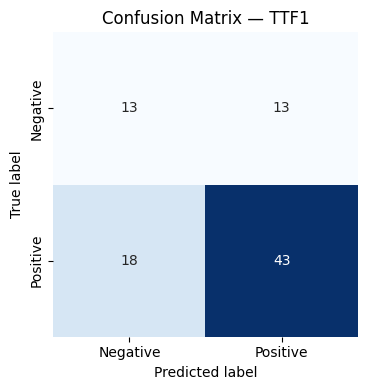


>>> FINAL REPORT: CK7 (Threshold: 0.5)
Accuracy : 54.02% (47/87)
Precision: 0.5217
Recall   : 0.5714
F1-Score : 0.5455
Confusion Matrix [[TN FP] [FN TP]]:
[[23 22]
 [18 24]]


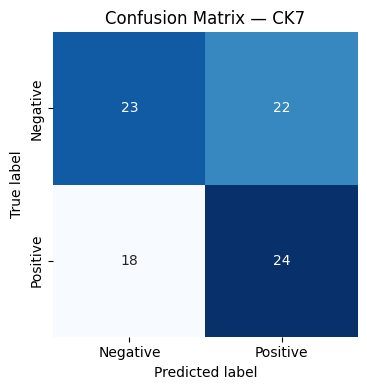

In [ ]:
MODEL_PATH_GOOD = "/content/drive/MyDrive/Colab Notebooks/model_ct_radiomics_nou.keras"

print(f"Load model: {MODEL_PATH_GOOD} ...")

try:
    loaded_model = tf.keras.models.load_model(MODEL_PATH_GOOD)
    print("Successfully loaded model!")
except Exception as e:
    print(f"Try without compilation: {e}")
    loaded_model = tf.keras.models.load_model(MODEL_PATH_GOOD, compile=False)
    print("Successfully loaded model! No compilation")

evaluate_full_dataset(
    model=loaded_model,
    ct_paths=ct_paths,
    X_radio=X_radio,
    y=y,
    codes=codes,
    threshold_ttf1=0.7,
    threshold_ck7=0.5
)

Loaded model from: /content/drive/MyDrive/Colab Notebooks/model_ct_radiomics_nou.keras


/usr/local/lib/python3.12/dist-packages/keras/src/trainers/epoch_iterator.py:160: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self._interrupted_warning()


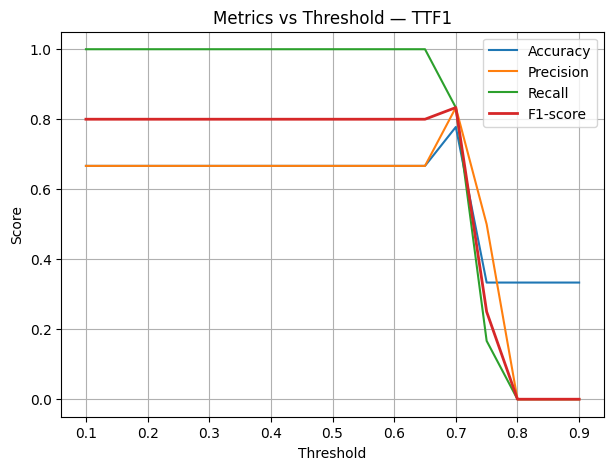

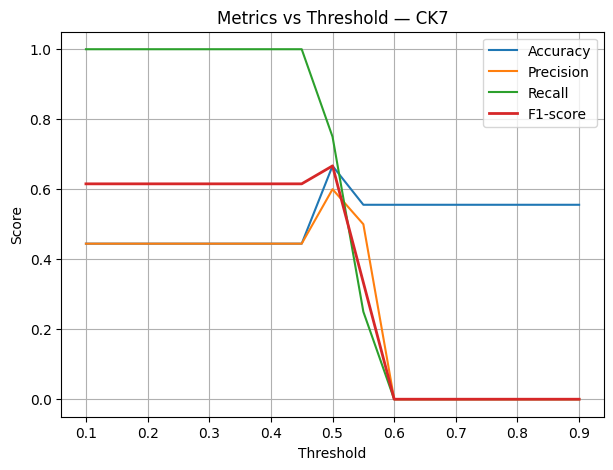

In [ ]:
MODEL_PATH = "/content/drive/MyDrive/Colab Notebooks/model_ct_radiomics_nou.keras"
model = tf.keras.models.load_model(MODEL_PATH)
print("Loaded model from:", MODEL_PATH)

y_true_ttf1, y_true_ck7 = [], []
for _, targets in test_ds.unbatch().map(lambda x, t: (0, t)):
    y_true_ttf1.append(float(targets["TTF1"].numpy()[0]))
    y_true_ck7.append(float(targets["CK7"].numpy()[0]))
y_true_ttf1 = np.array(y_true_ttf1, dtype=int)
y_true_ck7 = np.array(y_true_ck7, dtype=int)

pred = model.predict(test_ds, verbose=0)
p_test_ttf1 = pred["TTF1"].ravel()
p_test_ck7 = pred["CK7"].ravel()

def plot_threshold_metrics(y_true, y_prob, name):
    thresholds = np.arange(0.10, 0.91, 0.05)
    acc, prec, rec, f1 = [], [], [], []
    for t in thresholds:
        y_pred = (y_prob >= t).astype(int)
        acc.append(accuracy_score(y_true, y_pred))
        prec.append(precision_score(y_true, y_pred, zero_division=0))
        rec.append(recall_score(y_true, y_pred, zero_division=0))
        f1.append(f1_score(y_true, y_pred, zero_division=0))

    plt.figure(figsize=(7,5))
    plt.plot(thresholds, acc,  label="Accuracy")
    plt.plot(thresholds, prec, label="Precision")
    plt.plot(thresholds, rec,  label="Recall")
    plt.plot(thresholds, f1,   label="F1-score", linewidth=2)
    plt.xlabel("Threshold")
    plt.ylabel("Score")
    plt.title(f"Metrics vs Threshold — {name}")
    plt.legend()
    plt.grid(True)
    plt.show()

plot_threshold_metrics(y_true_ttf1,   p_test_ttf1,   "TTF1")
plot_threshold_metrics(y_true_ck7, p_test_ck7, "CK7")


Load model: /content/drive/MyDrive/Colab Notebooks/model_TTF1_CK7_CT_radiomics_1.keras ...
Successfully loaded model!

--- Generating dataset for all 87 patients ---

Running Prediction...
44/44 ━━━━━━━━━━━━━━━━━━━━ 37s 790ms/step

PATIENT ID      | MARKER | TRUE     | PRED CLS   | PROB (%)   | RESULT
2011            | TTF1   | 1        | 1          | 0.7172     | ✅
                | CK7    | 0        | 1          | 0.5415     | ❌
-----------------------------------------------------------------------------------------------
3111            | TTF1   | 1        | 1          | 0.7260     | ✅
                | CK7    | 1        | 1          | 0.5683     | ✅
-----------------------------------------------------------------------------------------------
4111            | TTF1   | 1        | 1          | 0.8440     | ✅
                | CK7    | 0        | 0          | 0.3977     | ✅
-----------------------------------------------------------------------------------------------
5111         

/usr/local/lib/python3.12/dist-packages/keras/src/trainers/epoch_iterator.py:160: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self._interrupted_warning()


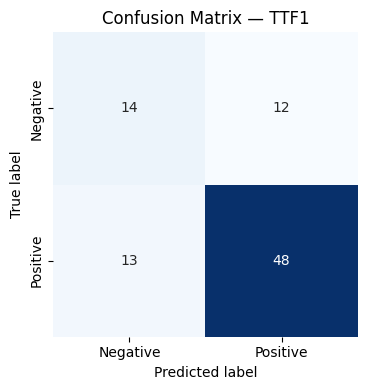


>>> FINAL REPORT: CK7 (Threshold: 0.5)
Accuracy : 65.52% (57/87)
Precision: 0.5968
Recall   : 0.8810
F1-Score : 0.7115
Confusion Matrix [[TN FP] [FN TP]]:
[[20 25]
 [ 5 37]]


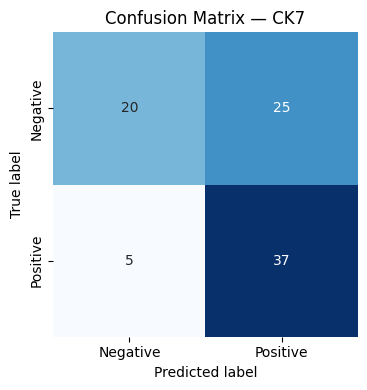

In [ ]:
MODEL_PATH_GOOD = "/content/drive/MyDrive/Colab Notebooks/model_TTF1_CK7_CT_radiomics_1.keras"

print(f"Load model: {MODEL_PATH_GOOD} ...")

try:
    loaded_model = tf.keras.models.load_model(MODEL_PATH_GOOD)
    print("Successfully loaded model!")
except Exception as e:
    print(f"Try without compilation: {e}")
    loaded_model = tf.keras.models.load_model(MODEL_PATH_GOOD, compile=False)
    print("Successfully loaded model! No compilation")

evaluate_full_dataset(
    model=loaded_model,
    ct_paths=ct_paths,
    X_radio=X_radio,
    y=y,
    codes=codes,
    threshold_ttf1=0.7,
    threshold_ck7=0.5
)

Loaded model from: /content/drive/MyDrive/Colab Notebooks/model_TTF1_CK7_CT_radiomics_1.keras


/usr/local/lib/python3.12/dist-packages/keras/src/trainers/epoch_iterator.py:160: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self._interrupted_warning()


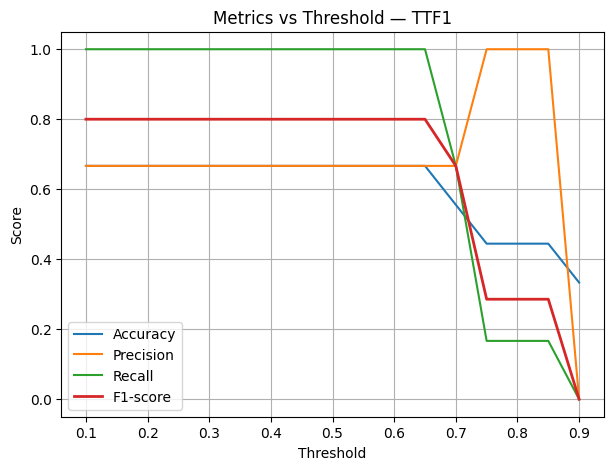

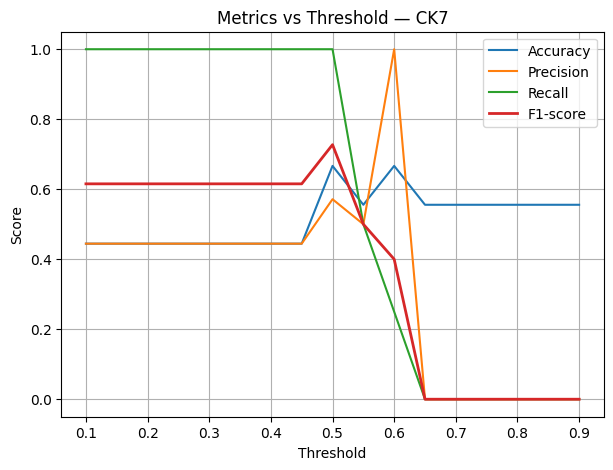

In [ ]:

MODEL_PATH = "/content/drive/MyDrive/Colab Notebooks/model_TTF1_CK7_CT_radiomics_1.keras"
model = tf.keras.models.load_model(MODEL_PATH)
print("Loaded model from:", MODEL_PATH)

y_true_ttf1, y_true_ck7 = [], []
for _, targets in test_ds.unbatch().map(lambda x, t: (0, t)):
    y_true_ttf1.append(float(targets["TTF1"].numpy()[0]))
    y_true_ck7.append(float(targets["CK7"].numpy()[0]))
y_true_ttf1 = np.array(y_true_ttf1, dtype=int)
y_true_ck7 = np.array(y_true_ck7, dtype=int)

pred = model.predict(test_ds, verbose=0)
p_test_ttf1 = pred["TTF1"].ravel()
p_test_ck7 = pred["CK7"].ravel()

def plot_threshold_metrics(y_true, y_prob, name):
    thresholds = np.arange(0.10, 0.91, 0.05)
    acc, prec, rec, f1 = [], [], [], []
    for t in thresholds:
        y_pred = (y_prob >= t).astype(int)
        acc.append(accuracy_score(y_true, y_pred))
        prec.append(precision_score(y_true, y_pred, zero_division=0))
        rec.append(recall_score(y_true, y_pred, zero_division=0))
        f1.append(f1_score(y_true, y_pred, zero_division=0))

    plt.figure(figsize=(7,5))
    plt.plot(thresholds, acc,  label="Accuracy")
    plt.plot(thresholds, prec, label="Precision")
    plt.plot(thresholds, rec,  label="Recall")
    plt.plot(thresholds, f1,   label="F1-score", linewidth=2)
    plt.xlabel("Threshold")
    plt.ylabel("Score")
    plt.title(f"Metrics vs Threshold — {name}")
    plt.legend()
    plt.grid(True)
    plt.show()

plot_threshold_metrics(y_true_ttf1,   p_test_ttf1,   "TTF1")
plot_threshold_metrics(y_true_ck7, p_test_ck7, "CK7")


/tmp/ipython-input-1408454679.py:3: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  y_true_ttf1.append(float(targets["TTF1"].numpy()))
/tmp/ipython-input-1408454679.py:4: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  y_true_ck7.append(float(targets["CK7"].numpy()))


5/5 ━━━━━━━━━━━━━━━━━━━━ 4s 774ms/step

TTF1 — binary metrics
Accuracy:  0.5556
Precision: 0.6667
Recall:    0.6667
F1-score:  0.6667
Confusion matrix [[TN FP] [FN TP]]:
[[1 2]
 [2 4]]


/usr/local/lib/python3.12/dist-packages/keras/src/trainers/epoch_iterator.py:160: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self._interrupted_warning()


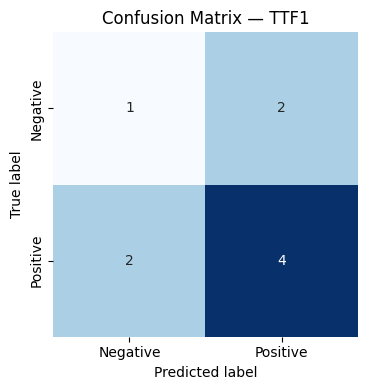


CK7 — binary metrics
Accuracy:  0.6667
Precision: 0.5714
Recall:    1.0000
F1-score:  0.7273
Confusion matrix [[TN FP] [FN TP]]:
[[2 3]
 [0 4]]


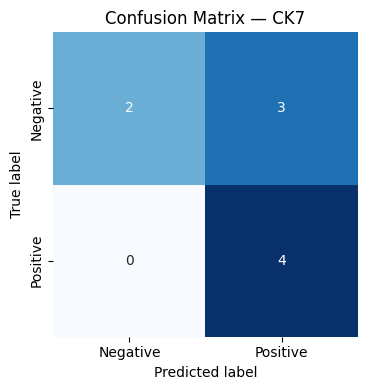

In [ ]:
y_true_ttf1, y_true_ck7 = [], []
for (_, _), targets in test_ds.unbatch():
    y_true_ttf1.append(float(targets["TTF1"].numpy()))
    y_true_ck7.append(float(targets["CK7"].numpy()))
y_true_ttf1 = np.array(y_true_ttf1, dtype=int)
y_true_ck7 = np.array(y_true_ck7, dtype=int)

pred = model.predict(test_ds)
y_pred_ttf1 = (pred["TTF1"].ravel()   >= 0.7).astype(int)
y_pred_ck7 = (pred["CK7"].ravel() >= 0.5).astype(int)

def plot_confusion_matrix(y_true, y_pred, name):
    cm = confusion_matrix(y_true, y_pred)
    labels = ["Negative", "Positive"]

    plt.figure(figsize=(4.5, 4))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False,
                xticklabels=labels, yticklabels=labels, square=True)
    plt.xlabel("Predicted label")
    plt.ylabel("True label")
    plt.title(f"Confusion Matrix — {name}")
    plt.tight_layout()
    plt.show()

def print_binary_metrics(y_true, y_pred, name):
    acc = accuracy_score(y_true, y_pred)
    prec = precision_score(y_true, y_pred, zero_division=0)
    rec = recall_score(y_true, y_pred, zero_division=0)
    f1 = f1_score(y_true, y_pred, zero_division=0)
    cm = confusion_matrix(y_true, y_pred)

    print(f"\n{name} — binary metrics")
    print(f"Accuracy:  {acc:.4f}")
    print(f"Precision: {prec:.4f}")
    print(f"Recall:    {rec:.4f}")
    print(f"F1-score:  {f1:.4f}")
    print("Confusion matrix [[TN FP] [FN TP]]:")
    print(cm)

    plot_confusion_matrix(y_true, y_pred, name)

print_binary_metrics(y_true_ttf1,   y_pred_ttf1,   "TTF1")
print_binary_metrics(y_true_ck7, y_pred_ck7, "CK7")

In [ ]:
train_ds, val_ds, test_ds = prepare_stratified_datasets(
    data_index,
    ct_paths,
    X_radio,
    y,
    val_split=0.15,
    test_split=0.10
)


--- TOTAL PACIENTI DISPONIBILI: 87 ---
stratify_key
0.0_0.0    14
0.0_1.0    12
1.0_0.0    31
1.0_1.0    30
Name: count, dtype: int64
----------------------------------------

=== RAPORT DISTRIBUTIE DUPA SPLIT ===

Set: TRAIN (Total: 65)
  -> TTF1: 0.0 | CK7: 0.0 : 11 pacienti
  -> TTF1: 0.0 | CK7: 1.0 : 9 pacienti
  -> TTF1: 1.0 | CK7: 0.0 : 23 pacienti
  -> TTF1: 1.0 | CK7: 1.0 : 22 pacienti

Set: VALIDATION (Total: 13)
  -> TTF1: 0.0 | CK7: 0.0 : 2 pacienti
  -> TTF1: 0.0 | CK7: 1.0 : 2 pacienti
  -> TTF1: 1.0 | CK7: 0.0 : 5 pacienti
  -> TTF1: 1.0 | CK7: 1.0 : 4 pacienti

Set: TEST (Total: 9)
  -> TTF1: 0.0 | CK7: 0.0 : 1 pacienti
  -> TTF1: 0.0 | CK7: 1.0 : 1 pacienti
  -> TTF1: 1.0 | CK7: 0.0 : 3 pacienti
  -> TTF1: 1.0 | CK7: 1.0 : 4 pacienti




In [ ]:
def conv3d_block(x, filters, k=3, s=1, p="same"):
    x = tf.keras.layers.Conv3D(filters, k, strides=s, padding=p)(x)
    x = tf.keras.layers.BatchNormalization()(x)
    x = tf.keras.layers.Activation("relu")(x)
    return x


def build_multimodal_twoheads(radio_dim, input_shape):
    """3D CNN + MLP with two independent heads (TTF1, CK7)."""
    # CT branch
    in_ct = tf.keras.Input(shape=input_shape, name="ct")
    x = conv3d_block(in_ct, 16); x = conv3d_block(x, 16); x = tf.keras.layers.MaxPool3D(2)(x)
    x = conv3d_block(x, 32); x = conv3d_block(x, 32); x = tf.keras.layers.MaxPool3D(2)(x)
    x = conv3d_block(x, 64); x = conv3d_block(x, 64); x = tf.keras.layers.MaxPool3D(2)(x)
    x = conv3d_block(x, 128); x = tf.keras.layers.GlobalAveragePooling3D()(x)
    x = tf.keras.layers.Dense(128, activation="relu")(x)
    x = tf.keras.layers.Dropout(0.3)(x)

    # Radiomics branch
    in_radio = tf.keras.Input(shape=(radio_dim,), name="radio")
    r = tf.keras.layers.Dense(256, activation="relu")(in_radio)
    r = tf.keras.layers.Dropout(0.3)(r)
    r = tf.keras.layers.Dense(128, activation="relu")(r)

    # Fusion
    z = tf.keras.layers.Concatenate()([x, r])
    z = tf.keras.layers.Dense(128, activation="relu")(z)
    z = tf.keras.layers.Dropout(0.3)(z)

    # Heads
    out_ttf1 = tf.keras.layers.Dense(1, activation="sigmoid", name="TTF1")(z)
    out_ck7 = tf.keras.layers.Dense(1, activation="sigmoid", name="CK7")(z)

    model = tf.keras.Model(inputs=[in_ct, in_radio],
                           outputs={"TTF1": out_ttf1, "CK7": out_ck7})

    model.compile(
        optimizer=tf.keras.optimizers.Adam(LR),
        loss={"TTF1": "binary_crossentropy", "CK7": "binary_crossentropy"},
        metrics={
            "TTF1": [tf.keras.metrics.AUC(name="AUC"), tf.keras.metrics.BinaryAccuracy(name="BinAcc", threshold=0.5)],
            "CK7": [tf.keras.metrics.AUC(name="AUC"), tf.keras.metrics.BinaryAccuracy(name="BinAcc", threshold=0.5)],
        }
    )
    return model

In [ ]:
MODEL_PATH = "/content/drive/MyDrive/Colab Notebooks/model_TTF1_CK7_CT_radiomics_2.keras"

In [ ]:
MODEL_PATH = "/content/drive/MyDrive/Colab Notebooks/model_TTF1_CK7_CT_radiomics_2.keras"
EPOCHS = 10

# Build model
model = build_multimodal_twoheads(radio_dim=X_radio.shape[1], input_shape=TARGET_SHAPE+(1,))
model.summary()

callbacks = [
    tf.keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=3, verbose=1),
    tf.keras.callbacks.EarlyStopping(monitor="val_loss", patience=8, restore_best_weights=True),
    tf.keras.callbacks.ModelCheckpoint(MODEL_PATH, monitor="val_loss", save_best_only=True)
]

# Train
history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS,
    callbacks=callbacks
)

print("Evaluation on test set:")
test_metrics = model.evaluate(test_ds, return_dict=True)
print(test_metrics)

pred = model.predict(test_ds)
print("Sample predictions (first 5):")
print("TTF1:", pred["TTF1"][:5, 0])
print("CK7:", pred["CK7"][:5, 0])

print("Best model saved to:", MODEL_PATH)


Model: "functional_2"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ ct (InputLayer)     │ (None, 128, 128,  │          0 │ -                 │
│                     │ 128, 1)           │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv3d_14 (Conv3D)  │ (None, 128, 128,  │        448 │ ct[0][0]          │
│                     │ 128, 16)          │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 128, 128,  │         64 │ conv3d_14[0][0]   │
│ (BatchNormalizatio… │ 128, 16)          │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_14       │ (None, 128, 128,  │          0 │ batch_normalizat… │
│ (Activation)        │ 128, 16)          │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv3d_15 (Conv3D)  │ (None, 128, 128,  │      6,928 │ activation_14[0]… │
│                     │ 128, 16)          │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 128, 128,  │         64 │ conv3d_15[0][0]   │
│ (BatchNormalizatio… │ 128, 16)          │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_15       │ (None, 128, 128,  │          0 │ batch_normalizat… │
│ (Activation)        │ 128, 16)          │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling3d_6     │ (None, 64, 64,    │          0 │ activation_15[0]… │
│ (MaxPooling3D)      │ 64, 16)           │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv3d_16 (Conv3D)  │ (None, 64, 64,    │     13,856 │ max_pooling3d_6[… │
│                     │ 64, 32)           │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 64, 64,    │        128 │ conv3d_16[0][0]   │
│ (BatchNormalizatio… │ 64, 32)           │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_16       │ (None, 64, 64,    │          0 │ batch_normalizat… │
│ (Activation)        │ 64, 32)           │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv3d_17 (Conv3D)  │ (None, 64, 64,    │     27,680 │ activation_16[0]… │
│                     │ 64, 32)           │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 64, 64,    │        128 │ conv3d_17[0][0]   │
│ (BatchNormalizatio… │ 64, 32)           │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_17       │ (None, 64, 64,    │          0 │ batch_normalizat… │
│ (Activation)        │ 64, 32)           │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling3d_7     │ (None, 32, 32,    │          0 │ activation_17[0]… │
│ (MaxPooling3D)      │ 32, 32)           │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv3d_18 (Conv3D)  │ (None, 32, 32,    │     55,360 │ max_pooling3d_7[… │
│                     │ 32, 64)           │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 32, 32,    │        256 │ conv3d_18[0][0] 

 Total params: 547,858 (2.09 MB)

 Trainable params: 547,154 (2.09 MB)

 Non-trainable params: 704 (2.75 KB)

Epoch 1/10
     33/Unknown 54s 550ms/step - CK7_AUC: 0.4246 - CK7_BinAcc: 0.4751 - CK7_loss: 0.7203 - TTF1_AUC: 0.4205 - TTF1_BinAcc: 0.3228 - TTF1_loss: 0.8230 - loss: 1.5433

/usr/local/lib/python3.12/dist-packages/keras/src/trainers/epoch_iterator.py:160: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self._interrupted_warning()


33/33 ━━━━━━━━━━━━━━━━━━━━ 63s 824ms/step - CK7_AUC: 0.4260 - CK7_BinAcc: 0.4751 - CK7_loss: 0.7203 - TTF1_AUC: 0.4201 - TTF1_BinAcc: 0.3237 - TTF1_loss: 0.8222 - loss: 1.5423 - val_CK7_AUC: 0.2857 - val_CK7_BinAcc: 0.3846 - val_CK7_loss: 0.7209 - val_TTF1_AUC: 0.1806 - val_TTF1_BinAcc: 0.6154 - val_TTF1_loss: 0.6840 - val_loss: 1.4080 - learning_rate: 1.0000e-04
Epoch 2/10
33/33 ━━━━━━━━━━━━━━━━━━━━ 39s 515ms/step - CK7_AUC: 0.4726 - CK7_BinAcc: 0.4232 - CK7_loss: 0.7033 - TTF1_AUC: 0.4792 - TTF1_BinAcc: 0.6728 - TTF1_loss: 0.6774 - loss: 1.3808 - val_CK7_AUC: 0.3690 - val_CK7_BinAcc: 0.3846 - val_CK7_loss: 0.7136 - val_TTF1_AUC: 0.2778 - val_TTF1_BinAcc: 0.6923 - val_TTF1_loss: 0.6335 - val_loss: 1.3587 - learning_rate: 1.0000e-04
Epoch 3/10
33/33 ━━━━━━━━━━━━━━━━━━━━ 38s 514ms/step - CK7_AUC: 0.6128 - CK7_BinAcc: 0.5310 - CK7_loss: 0.6603 - TTF1_AUC: 0.6674 - TTF1_BinAcc: 0.7406 - TTF1_loss: 0.6026 - loss: 1.2631 - val_CK7_AUC: 0.3690 - val_CK7_BinAcc: 0.5385 - val_CK7_loss: 0.7043 

/tmp/ipython-input-1554707241.py:3: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  y_true_ttf1.append(float(targets["TTF1"].numpy()))
/tmp/ipython-input-1554707241.py:4: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  y_true_ck7.append(float(targets["CK7"].numpy()))


5/5 ━━━━━━━━━━━━━━━━━━━━ 3s 513ms/step

TTF1 — binary metrics
Accuracy:  0.5556
Precision: 0.7143
Recall:    0.7143
F1-score:  0.7143
Confusion matrix [[TN FP] [FN TP]]:
[[0 2]
 [2 5]]


/usr/local/lib/python3.12/dist-packages/keras/src/trainers/epoch_iterator.py:160: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self._interrupted_warning()


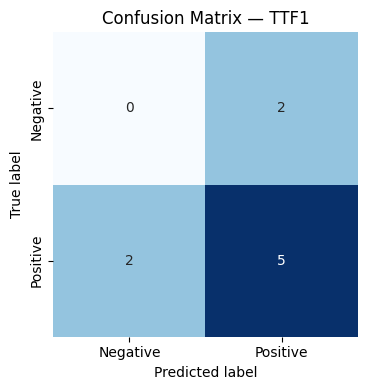


CK7 — binary metrics
Accuracy:  0.7778
Precision: 1.0000
Recall:    0.6000
F1-score:  0.7500
Confusion matrix [[TN FP] [FN TP]]:
[[4 0]
 [2 3]]


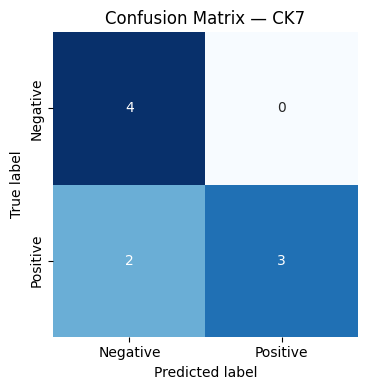

In [ ]:
y_true_ttf1, y_true_ck7 = [], []
for (_, _), targets in test_ds.unbatch():
    y_true_ttf1.append(float(targets["TTF1"].numpy()))
    y_true_ck7.append(float(targets["CK7"].numpy()))
y_true_ttf1 = np.array(y_true_ttf1, dtype=int)
y_true_ck7 = np.array(y_true_ck7, dtype=int)

pred = model.predict(test_ds)
y_pred_ttf1 = (pred["TTF1"].ravel()   >= 0.68).astype(int)
y_pred_ck7 = (pred["CK7"].ravel() >= 0.45).astype(int)

def plot_confusion_matrix(y_true, y_pred, name):
    cm = confusion_matrix(y_true, y_pred)
    labels = ["Negative", "Positive"]

    plt.figure(figsize=(4.5, 4))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False,
                xticklabels=labels, yticklabels=labels, square=True)
    plt.xlabel("Predicted label")
    plt.ylabel("True label")
    plt.title(f"Confusion Matrix — {name}")
    plt.tight_layout()
    plt.show()

def print_binary_metrics(y_true, y_pred, name):
    acc = accuracy_score(y_true, y_pred)
    prec = precision_score(y_true, y_pred, zero_division=0)
    rec = recall_score(y_true, y_pred, zero_division=0)
    f1 = f1_score(y_true, y_pred, zero_division=0)
    cm = confusion_matrix(y_true, y_pred)

    print(f"\n{name} — binary metrics")
    print(f"Accuracy:  {acc:.4f}")
    print(f"Precision: {prec:.4f}")
    print(f"Recall:    {rec:.4f}")
    print(f"F1-score:  {f1:.4f}")
    print("Confusion matrix [[TN FP] [FN TP]]:")
    print(cm)

    plot_confusion_matrix(y_true, y_pred, name)

print_binary_metrics(y_true_ttf1,   y_pred_ttf1,   "TTF1")
print_binary_metrics(y_true_ck7, y_pred_ck7, "CK7")

Loaded model from: /content/drive/MyDrive/Colab Notebooks/model_TTF1_CK7_CT_radiomics_2.keras


/usr/local/lib/python3.12/dist-packages/keras/src/trainers/epoch_iterator.py:160: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self._interrupted_warning()


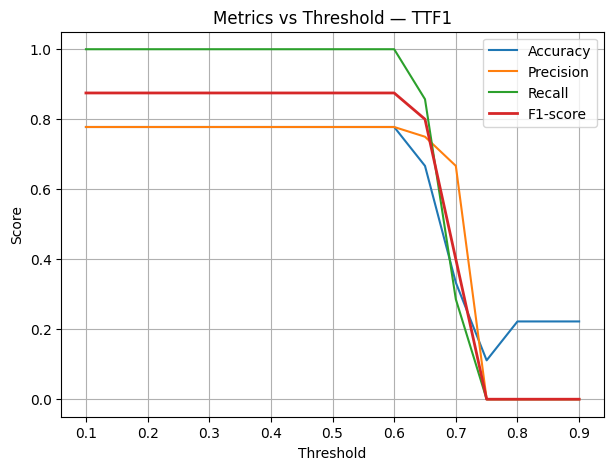

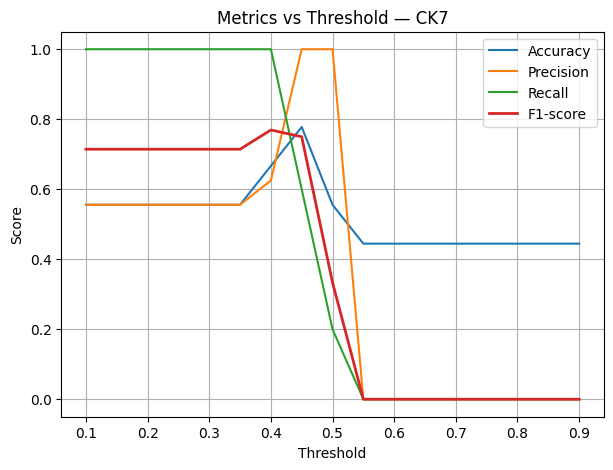

In [ ]:

MODEL_PATH = "/content/drive/MyDrive/Colab Notebooks/model_TTF1_CK7_CT_radiomics_2.keras"
model = tf.keras.models.load_model(MODEL_PATH)
print("Loaded model from:", MODEL_PATH)

y_true_ttf1, y_true_ck7 = [], []
for _, targets in test_ds.unbatch().map(lambda x, t: (0, t)):
    y_true_ttf1.append(float(targets["TTF1"].numpy()[0]))
    y_true_ck7.append(float(targets["CK7"].numpy()[0]))
y_true_ttf1 = np.array(y_true_ttf1, dtype=int)
y_true_ck7 = np.array(y_true_ck7, dtype=int)

pred = model.predict(test_ds, verbose=0)
p_test_ttf1 = pred["TTF1"].ravel()
p_test_ck7 = pred["CK7"].ravel()

def plot_threshold_metrics(y_true, y_prob, name):
    thresholds = np.arange(0.10, 0.91, 0.05)
    acc, prec, rec, f1 = [], [], [], []
    for t in thresholds:
        y_pred = (y_prob >= t).astype(int)
        acc.append(accuracy_score(y_true, y_pred))
        prec.append(precision_score(y_true, y_pred, zero_division=0))
        rec.append(recall_score(y_true, y_pred, zero_division=0))
        f1.append(f1_score(y_true, y_pred, zero_division=0))

    plt.figure(figsize=(7,5))
    plt.plot(thresholds, acc,  label="Accuracy")
    plt.plot(thresholds, prec, label="Precision")
    plt.plot(thresholds, rec,  label="Recall")
    plt.plot(thresholds, f1,   label="F1-score", linewidth=2)
    plt.xlabel("Threshold")
    plt.ylabel("Score")
    plt.title(f"Metrics vs Threshold — {name}")
    plt.legend()
    plt.grid(True)
    plt.show()

plot_threshold_metrics(y_true_ttf1,   p_test_ttf1,   "TTF1")
plot_threshold_metrics(y_true_ck7, p_test_ck7, "CK7")


In [ ]:
MODEL_PATH_GOOD = "/content/drive/MyDrive/Colab Notebooks/model_TTF1_CK7_CT_radiomics_2.keras"

print(f"Load model: {MODEL_PATH_GOOD} ...")

try:
    loaded_model = tf.keras.models.load_model(MODEL_PATH_GOOD)
    print("Successfully loaded model!")
except Exception as e:
    print(f"Try without compilation: {e}")
    loaded_model = tf.keras.models.load_model(MODEL_PATH_GOOD, compile=False)
    print("Successfully loaded model! No compilation")

evaluate_full_dataset(
    model=loaded_model,
    ct_paths=ct_paths,
    X_radio=X_radio,
    y=y,
    codes=codes,
    threshold_ttf1=0.7,
    threshold_ck7=0.5
)

In [ ]:
def conv3d_block(x, filters, k=3, s=1, p="same", l2_reg=1e-4):
    x = tf.keras.layers.Conv3D(
        filters,
        k,
        strides=s,
        padding=p,
        kernel_initializer="he_normal",
        kernel_regularizer=tf.keras.regularizers.l2(l2_reg),
    )(x)
    x = tf.keras.layers.BatchNormalization()(x)
    x = tf.keras.layers.Activation("relu")(x)
    return x


def build_multimodal_twoheads_small(radio_dim, input_shape, lr, l2_reg=1e-4, dropout_rate=0.4):

    in_ct = tf.keras.Input(shape=input_shape, name="ct")

    x = conv3d_block(in_ct, 8, l2_reg=l2_reg)
    x = conv3d_block(x, 8, l2_reg=l2_reg)
    x = tf.keras.layers.MaxPool3D(2)(x)

    x = conv3d_block(x, 16, l2_reg=l2_reg)
    x = conv3d_block(x, 16, l2_reg=l2_reg)
    x = tf.keras.layers.MaxPool3D(2)(x)

    x = conv3d_block(x, 32, l2_reg=l2_reg)
    x = tf.keras.layers.MaxPool3D(2)(x)

    x = tf.keras.layers.GlobalAveragePooling3D()(x)
    x = tf.keras.layers.Dense(
        64,
        activation="relu",
        kernel_regularizer=tf.keras.regularizers.l2(l2_reg),
    )(x)
    x = tf.keras.layers.Dropout(dropout_rate)(x)

    # ----- Radiomics branch (MLP mai mic + regularizare) -----
    in_radio = tf.keras.Input(shape=(radio_dim,), name="radio")

    r = tf.keras.layers.Dense(
        128,
        activation="relu",
        kernel_regularizer=tf.keras.regularizers.l2(l2_reg),
    )(in_radio)
    r = tf.keras.layers.Dropout(dropout_rate)(r)

    r = tf.keras.layers.Dense(
        64,
        activation="relu",
        kernel_regularizer=tf.keras.regularizers.l2(l2_reg),
    )(r)

    # ----- Fusion -----
    z = tf.keras.layers.Concatenate()([x, r])
    z = tf.keras.layers.Dense(
        64,
        activation="relu",
        kernel_regularizer=tf.keras.regularizers.l2(l2_reg),
    )(z)
    z = tf.keras.layers.Dropout(dropout_rate)(z)

    # ----- Heads -----
    out_ttf1 = tf.keras.layers.Dense(
        1,
        activation="sigmoid",
        name="TTF1",
        kernel_regularizer=tf.keras.regularizers.l2(l2_reg),
    )(z)

    out_ck7 = tf.keras.layers.Dense(
        1,
        activation="sigmoid",
        name="CK7",
        kernel_regularizer=tf.keras.regularizers.l2(l2_reg),
    )(z)

    model = tf.keras.Model(
        inputs=[in_ct, in_radio],
        outputs={"TTF1": out_ttf1, "CK7": out_ck7},
    )

    model.compile(
        optimizer=tf.keras.optimizers.Adam(lr),
        loss={"TTF1": "binary_crossentropy", "CK7": "binary_crossentropy"},
        metrics={
            "TTF1": [
                tf.keras.metrics.AUC(name="AUC"),
                tf.keras.metrics.BinaryAccuracy(name="BinAcc", threshold=0.5),
            ],
            "CK7": [
                tf.keras.metrics.AUC(name="AUC"),
                tf.keras.metrics.BinaryAccuracy(name="BinAcc", threshold=0.5),
            ],
        },
    )

    return model


In [ ]:
train_ds, val_ds, test_ds = prepare_stratified_datasets(
    data_index,
    ct_paths,
    X_radio,
    y,
    val_split=0.10,
    test_split=0.10
)


--- TOTAL PACIENTI DISPONIBILI: 87 ---
stratify_key
0.0_0.0    14
0.0_1.0    12
1.0_0.0    31
1.0_1.0    30
Name: count, dtype: int64
----------------------------------------

=== RAPORT DISTRIBUTIE DUPA SPLIT ===

Set: TRAIN (Total: 69)
  -> TTF1: 0.0 | CK7: 0.0 : 11 pacienti
  -> TTF1: 0.0 | CK7: 1.0 : 9 pacienti
  -> TTF1: 1.0 | CK7: 0.0 : 25 pacienti
  -> TTF1: 1.0 | CK7: 1.0 : 24 pacienti

Set: VALIDATION (Total: 9)
  -> TTF1: 0.0 | CK7: 0.0 : 1 pacienti
  -> TTF1: 0.0 | CK7: 1.0 : 2 pacienti
  -> TTF1: 1.0 | CK7: 0.0 : 3 pacienti
  -> TTF1: 1.0 | CK7: 1.0 : 3 pacienti

Set: TEST (Total: 9)
  -> TTF1: 0.0 | CK7: 0.0 : 2 pacienti
  -> TTF1: 0.0 | CK7: 1.0 : 1 pacienti
  -> TTF1: 1.0 | CK7: 0.0 : 3 pacienti
  -> TTF1: 1.0 | CK7: 1.0 : 3 pacienti




In [ ]:
MODEL_PATH = "/content/drive/MyDrive/Colab Notebooks/model_TTF1_CK7_CT_radiomics_mini.keras"
EPOCHS = 25

radio_dim = X_radio.shape[1]
model = build_multimodal_twoheads_small(
    radio_dim=radio_dim,
    input_shape=TARGET_SHAPE + (1,),
    lr=LR,
    l2_reg=1e-4,
    dropout_rate=0.4,
)


model.summary()

callbacks = [
    tf.keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=3, verbose=1),
    tf.keras.callbacks.EarlyStopping(monitor="val_loss", patience=8, restore_best_weights=True),
    tf.keras.callbacks.ModelCheckpoint(MODEL_PATH, monitor="val_loss", save_best_only=True)
]

# Train
history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS,
    callbacks=callbacks
)

print("Evaluation on test set:")
test_metrics = model.evaluate(test_ds, return_dict=True)
print(test_metrics)

pred = model.predict(test_ds)
print("Sample predictions (first 5):")
print("TTF1:", pred["TTF1"][:5, 0])
print("CK7:", pred["CK7"][:5, 0])

print("Best model saved to:", MODEL_PATH)



Model: "functional_3"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ ct (InputLayer)     │ (None, 128, 128,  │          0 │ -                 │
│                     │ 128, 1)           │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv3d_21 (Conv3D)  │ (None, 128, 128,  │        224 │ ct[0][0]          │
│                     │ 128, 8)           │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 128, 128,  │         32 │ conv3d_21[0][0]   │
│ (BatchNormalizatio… │ 128, 8)           │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_21       │ (None, 128, 128,  │          0 │ batch_normalizat… │
│ (Activation)        │ 128, 8)           │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv3d_22 (Conv3D)  │ (None, 128, 128,  │      1,736 │ activation_21[0]… │
│                     │ 128, 8)           │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 128, 128,  │         32 │ conv3d_22[0][0]   │
│ (BatchNormalizatio… │ 128, 8)           │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_22       │ (None, 128, 128,  │          0 │ batch_normalizat… │
│ (Activation)        │ 128, 8)           │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling3d_9     │ (None, 64, 64,    │          0 │ activation_22[0]… │
│ (MaxPooling3D)      │ 64, 8)            │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv3d_23 (Conv3D)  │ (None, 64, 64,    │      3,472 │ max_pooling3d_9[… │
│                     │ 64, 16)           │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 64, 64,    │         64 │ conv3d_23[0][0]   │
│ (BatchNormalizatio… │ 64, 16)           │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_23       │ (None, 64, 64,    │          0 │ batch_normalizat… │
│ (Activation)        │ 64, 16)           │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv3d_24 (Conv3D)  │ (None, 64, 64,    │      6,928 │ activation_23[0]… │
│                     │ 64, 16)           │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 64, 64,    │         64 │ conv3d_24[0][0]   │
│ (BatchNormalizatio… │ 64, 16)           │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_24       │ (None, 64, 64,    │          0 │ batch_normalizat… │
│ (Activation)        │ 64, 16)           │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling3d_10    │ (None, 32, 32,    │          0 │ activation_24[0]… │
│ (MaxPooling3D)      │ 32, 16)           │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv3d_25 (Conv3D)  │ (None, 32, 32,    │     13,856 │ max_pooling3d_10… │
│                     │ 32, 32)           │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 32, 32,    │        128 │ conv3d_25[0][0] 

 Total params: 59,114 (230.91 KB)

 Trainable params: 58,954 (230.29 KB)

 Non-trainable params: 160 (640.00 B)

Epoch 1/25
     35/Unknown 80s 677ms/step - CK7_AUC: 0.4381 - CK7_BinAcc: 0.5083 - CK7_loss: 0.7670 - TTF1_AUC: 0.2969 - TTF1_BinAcc: 0.6116 - TTF1_loss: 0.7079 - loss: 1.5240

/usr/local/lib/python3.12/dist-packages/keras/src/trainers/epoch_iterator.py:160: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self._interrupted_warning()


35/35 ━━━━━━━━━━━━━━━━━━━━ 86s 860ms/step - CK7_AUC: 0.4425 - CK7_BinAcc: 0.5095 - CK7_loss: 0.7663 - TTF1_AUC: 0.3014 - TTF1_BinAcc: 0.6115 - TTF1_loss: 0.7072 - loss: 1.5227 - val_CK7_AUC: 0.3750 - val_CK7_BinAcc: 0.5556 - val_CK7_loss: 0.7128 - val_TTF1_AUC: 0.5833 - val_TTF1_BinAcc: 0.5556 - val_TTF1_loss: 0.6541 - val_loss: 1.4301 - learning_rate: 1.0000e-04
Epoch 2/25
35/35 ━━━━━━━━━━━━━━━━━━━━ 39s 286ms/step - CK7_AUC: 0.3653 - CK7_BinAcc: 0.3094 - CK7_loss: 0.8481 - TTF1_AUC: 0.4053 - TTF1_BinAcc: 0.5938 - TTF1_loss: 0.6656 - loss: 1.5621 - val_CK7_AUC: 0.3000 - val_CK7_BinAcc: 0.5556 - val_CK7_loss: 0.7086 - val_TTF1_AUC: 0.6389 - val_TTF1_BinAcc: 0.6667 - val_TTF1_loss: 0.6366 - val_loss: 1.4096 - learning_rate: 1.0000e-04
Epoch 3/25
35/35 ━━━━━━━━━━━━━━━━━━━━ 36s 315ms/step - CK7_AUC: 0.3964 - CK7_BinAcc: 0.4199 - CK7_loss: 0.8039 - TTF1_AUC: 0.5817 - TTF1_BinAcc: 0.6183 - TTF1_loss: 0.6232 - loss: 1.4755 - val_CK7_AUC: 0.3000 - val_CK7_BinAcc: 0.5556 - val_CK7_loss: 0.7073 

Loaded model from: /content/drive/MyDrive/Colab Notebooks/model_TTF1_CK7_CT_radiomics_mini.keras


/usr/local/lib/python3.12/dist-packages/keras/src/trainers/epoch_iterator.py:160: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self._interrupted_warning()


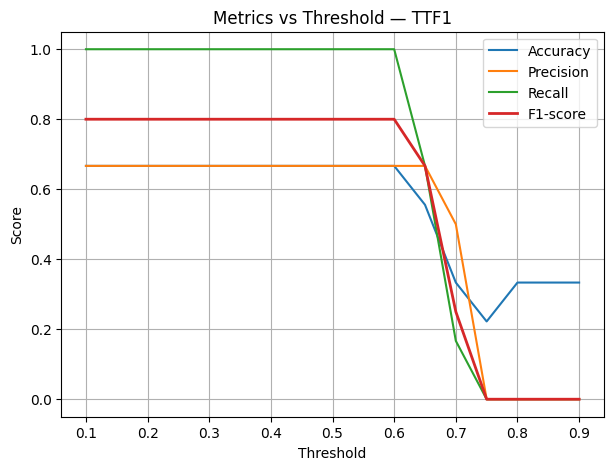

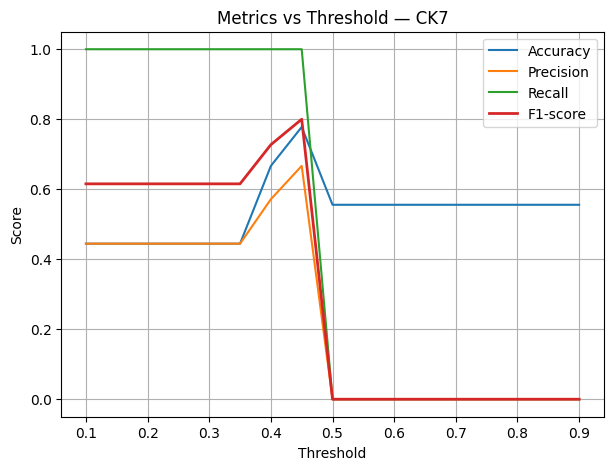

In [ ]:

MODEL_PATH = "/content/drive/MyDrive/Colab Notebooks/model_TTF1_CK7_CT_radiomics_mini.keras"
model = tf.keras.models.load_model(MODEL_PATH)
print("Loaded model from:", MODEL_PATH)

y_true_ttf1, y_true_ck7 = [], []
for _, targets in test_ds.unbatch().map(lambda x, t: (0, t)):
    y_true_ttf1.append(float(targets["TTF1"].numpy()[0]))
    y_true_ck7.append(float(targets["CK7"].numpy()[0]))
y_true_ttf1 = np.array(y_true_ttf1, dtype=int)
y_true_ck7 = np.array(y_true_ck7, dtype=int)

pred = model.predict(test_ds, verbose=0)
p_test_ttf1 = pred["TTF1"].ravel()
p_test_ck7 = pred["CK7"].ravel()

def plot_threshold_metrics(y_true, y_prob, name):
    thresholds = np.arange(0.10, 0.91, 0.05)
    acc, prec, rec, f1 = [], [], [], []
    for t in thresholds:
        y_pred = (y_prob >= t).astype(int)
        acc.append(accuracy_score(y_true, y_pred))
        prec.append(precision_score(y_true, y_pred, zero_division=0))
        rec.append(recall_score(y_true, y_pred, zero_division=0))
        f1.append(f1_score(y_true, y_pred, zero_division=0))

    plt.figure(figsize=(7,5))
    plt.plot(thresholds, acc,  label="Accuracy")
    plt.plot(thresholds, prec, label="Precision")
    plt.plot(thresholds, rec,  label="Recall")
    plt.plot(thresholds, f1,   label="F1-score", linewidth=2)
    plt.xlabel("Threshold")
    plt.ylabel("Score")
    plt.title(f"Metrics vs Threshold — {name}")
    plt.legend()
    plt.grid(True)
    plt.show()

plot_threshold_metrics(y_true_ttf1,   p_test_ttf1,   "TTF1")
plot_threshold_metrics(y_true_ck7, p_test_ck7, "CK7")


/tmp/ipython-input-1424821464.py:3: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  y_true_ttf1.append(float(targets["TTF1"].numpy()))
/tmp/ipython-input-1424821464.py:4: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  y_true_ck7.append(float(targets["CK7"].numpy()))


5/5 ━━━━━━━━━━━━━━━━━━━━ 4s 819ms/step

TTF1 — binary metrics
Accuracy:  0.6667
Precision: 0.8000
Recall:    0.6667
F1-score:  0.7273
Confusion matrix [[TN FP] [FN TP]]:
[[2 1]
 [2 4]]


/usr/local/lib/python3.12/dist-packages/keras/src/trainers/epoch_iterator.py:160: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self._interrupted_warning()


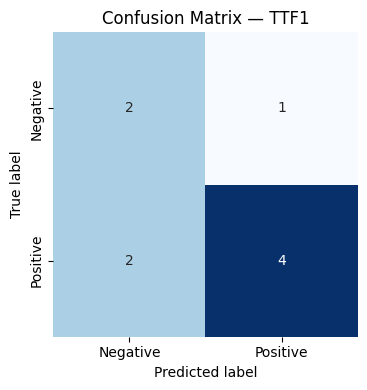


CK7 — binary metrics
Accuracy:  0.8889
Precision: 1.0000
Recall:    0.7500
F1-score:  0.8571
Confusion matrix [[TN FP] [FN TP]]:
[[5 0]
 [1 3]]


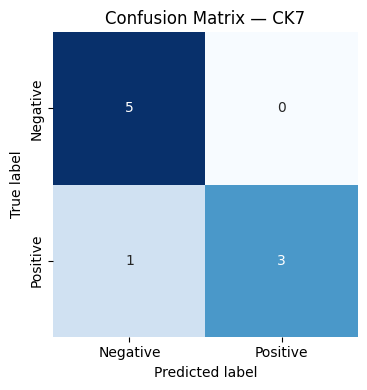

In [ ]:
y_true_ttf1, y_true_ck7 = [], []
for (_, _), targets in test_ds.unbatch():
    y_true_ttf1.append(float(targets["TTF1"].numpy()))
    y_true_ck7.append(float(targets["CK7"].numpy()))
y_true_ttf1 = np.array(y_true_ttf1, dtype=int)
y_true_ck7 = np.array(y_true_ck7, dtype=int)

pred = model.predict(test_ds)
y_pred_ttf1 = (pred["TTF1"].ravel()   >= 0.67).astype(int) # 67
y_pred_ck7 = (pred["CK7"].ravel() >= 0.48).astype(int) # 48

def plot_confusion_matrix(y_true, y_pred, name):
    cm = confusion_matrix(y_true, y_pred)
    labels = ["Negative", "Positive"]

    plt.figure(figsize=(4.5, 4))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False,
                xticklabels=labels, yticklabels=labels, square=True)
    plt.xlabel("Predicted label")
    plt.ylabel("True label")
    plt.title(f"Confusion Matrix — {name}")
    plt.tight_layout()
    plt.show()

def print_binary_metrics(y_true, y_pred, name):
    acc = accuracy_score(y_true, y_pred)
    prec = precision_score(y_true, y_pred, zero_division=0)
    rec = recall_score(y_true, y_pred, zero_division=0)
    f1 = f1_score(y_true, y_pred, zero_division=0)
    cm = confusion_matrix(y_true, y_pred)

    print(f"\n{name} — binary metrics")
    print(f"Accuracy:  {acc:.4f}")
    print(f"Precision: {prec:.4f}")
    print(f"Recall:    {rec:.4f}")
    print(f"F1-score:  {f1:.4f}")
    print("Confusion matrix [[TN FP] [FN TP]]:")
    print(cm)

    plot_confusion_matrix(y_true, y_pred, name)

print_binary_metrics(y_true_ttf1,   y_pred_ttf1,   "TTF1")
print_binary_metrics(y_true_ck7, y_pred_ck7, "CK7")

In [ ]:
# EFFICIENT NET

In [ ]:
IMG_SIZE = 128

def volume_to_efficientnet_input(vol):
    vol = vol[..., 0]

    d, h, w = vol.shape

    axial   = vol[d // 2, :, :]
    coronal = vol[:, h // 2, :]
    sagital = vol[:, :, w // 2]

    stacked = tf.stack([axial, coronal, sagital], axis=-1)

    stacked = tf.cast(stacked, tf.float32)
    stacked = tf.image.resize(stacked, (IMG_SIZE, IMG_SIZE))

    return stacked


In [ ]:
def make_dataset(ct_paths, X_radio, y, batch_size, shuffle=False):
    output_signature = (
        (
            tf.TensorSpec(shape=TARGET_SHAPE+(1,), dtype=tf.float32),
            tf.TensorSpec(shape=(X_radio.shape[1],), dtype=tf.float32),
        ),
        {
            "TTF1": tf.TensorSpec(shape=(), dtype=tf.float32),
            "CK7": tf.TensorSpec(shape=(), dtype=tf.float32),
        }
    )

    ds = tf.data.Dataset.from_generator(
        lambda: sample_generator(ct_paths, X_radio, y),
        output_signature=output_signature
    )

    if shuffle:
        ds = ds.shuffle(buffer_size=min(256, len(ct_paths)))

    def preprocess(inputs, targets):
        vol, radio = inputs                   # vol: (128,128,128,1)
        img2d = volume_to_efficientnet_input(vol)  # (128,128,3)

        new_targets = {
            "TTF1": tf.expand_dims(targets["TTF1"], -1),
            "CK7": tf.expand_dims(targets["CK7"], -1),
        }
        return (img2d, radio), new_targets    # img2d va merge în EfficientNet

    ds = ds.map(preprocess, num_parallel_calls=AUTOTUNE)
    ds = ds.batch(batch_size).prefetch(AUTOTUNE)
    return ds


In [ ]:
def build_multimodal_efficientnet_twoheads(radio_dim, lr=1e-4,
                                           base_trainable=False,
                                           dropout_rate=0.4, l2_reg=1e-4):

    # --------- CT branch: EfficientNetB0 2D ----------
    base_model = tf.keras.applications.EfficientNetB0(
        include_top=False,
        weights="imagenet",
        input_shape=(IMG_SIZE, IMG_SIZE, 3),
        pooling="avg"
    )
    base_model.trainable = base_trainable  # de început: False, apoi poți unfreeze ultimele blocuri

    in_ct2d = tf.keras.Input(shape=(IMG_SIZE, IMG_SIZE, 3), name="ct")

    # optional: rescale la [0,1] sau [-1,1]; la tine volumul e deja normalizat
    x = base_model(in_ct2d, training=False)
    x = tf.keras.layers.Dense(
        64, activation="relu",
        kernel_regularizer=tf.keras.regularizers.l2(l2_reg)
    )(x)
    x = tf.keras.layers.Dropout(dropout_rate)(x)

    # --------- Radiomics branch ----------
    in_radio = tf.keras.Input(shape=(radio_dim,), name="radio")

    r = tf.keras.layers.Dense(
        128, activation="relu",
        kernel_regularizer=tf.keras.regularizers.l2(l2_reg)
    )(in_radio)
    r = tf.keras.layers.Dropout(dropout_rate)(r)

    r = tf.keras.layers.Dense(
        64, activation="relu",
        kernel_regularizer=tf.keras.regularizers.l2(l2_reg)
    )(r)

    # --------- Fusion ----------
    z = tf.keras.layers.Concatenate()([x, r])
    z = tf.keras.layers.Dense(
        64, activation="relu",
        kernel_regularizer=tf.keras.regularizers.l2(l2_reg)
    )(z)
    z = tf.keras.layers.Dropout(dropout_rate)(z)

    # --------- Heads ----------
    out_ttf1 = tf.keras.layers.Dense(
        1, activation="sigmoid", name="TTF1",
        kernel_regularizer=tf.keras.regularizers.l2(l2_reg)
    )(z)

    out_ck7 = tf.keras.layers.Dense(
        1, activation="sigmoid", name="CK7",
        kernel_regularizer=tf.keras.regularizers.l2(l2_reg)
    )(z)

    model = tf.keras.Model(
        inputs=[in_ct2d, in_radio],
        outputs={"TTF1": out_ttf1, "CK7": out_ck7}
    )

    model.compile(
        optimizer=tf.keras.optimizers.Adam(lr),
        loss={"TTF1": "binary_crossentropy", "CK7": "binary_crossentropy"},
        metrics={
            "TTF1": [
                tf.keras.metrics.AUC(name="AUC"),
                tf.keras.metrics.BinaryAccuracy(name="BinAcc", threshold=0.5),
            ],
            "CK7": [
                tf.keras.metrics.AUC(name="AUC"),
                tf.keras.metrics.BinaryAccuracy(name="BinAcc", threshold=0.5),
            ],
        }
    )

    return model


In [ ]:
MODEL_PATH = "/content/drive/MyDrive/Colab Notebooks/model_EfficientNet.keras"
EPOCHS = 25

train_ds, val_ds, test_ds = prepare_stratified_datasets(
    data_index, ct_paths, X_radio, y,
    val_split=0.15, test_split=0.15
)


radio_dim = X_radio.shape[1]
model = build_multimodal_efficientnet_twoheads(
    radio_dim=radio_dim,
    lr=1e-4,
    base_trainable=False,
    dropout_rate=0.4,
    l2_reg=1e-4
)


model.summary()

callbacks = [
    tf.keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=3, verbose=1),
    tf.keras.callbacks.EarlyStopping(monitor="val_loss", patience=8, restore_best_weights=True),
    tf.keras.callbacks.ModelCheckpoint(MODEL_PATH, monitor="val_loss", save_best_only=True)
]

# Train
history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS,
    callbacks=callbacks
)

print("Evaluation on test set:")
test_metrics = model.evaluate(test_ds, return_dict=True)
print(test_metrics)

pred = model.predict(test_ds)
print("Sample predictions (first 5):")
print("TTF1:", pred["TTF1"][:5, 0])
print("CK7:", pred["CK7"][:5, 0])

print("Best model saved to:", MODEL_PATH)

--- TOTAL PACIENTI DISPONIBILI: 87 ---
stratify_key
0.0_0.0    14
0.0_1.0    12
1.0_0.0    31
1.0_1.0    30
Name: count, dtype: int64
----------------------------------------

=== RAPORT DISTRIBUTIE DUPA SPLIT ===

Set: TRAIN (Total: 60)
  -> TTF1: 0.0 | CK7: 0.0 : 10 pacienti
  -> TTF1: 0.0 | CK7: 1.0 : 8 pacienti
  -> TTF1: 1.0 | CK7: 0.0 : 21 pacienti
  -> TTF1: 1.0 | CK7: 1.0 : 21 pacienti

Set: VALIDATION (Total: 13)
  -> TTF1: 0.0 | CK7: 0.0 : 2 pacienti
  -> TTF1: 0.0 | CK7: 1.0 : 2 pacienti
  -> TTF1: 1.0 | CK7: 0.0 : 5 pacienti
  -> TTF1: 1.0 | CK7: 1.0 : 4 pacienti

Set: TEST (Total: 14)
  -> TTF1: 0.0 | CK7: 0.0 : 2 pacienti
  -> TTF1: 0.0 | CK7: 1.0 : 2 pacienti
  -> TTF1: 1.0 | CK7: 0.0 : 5 pacienti
  -> TTF1: 1.0 | CK7: 1.0 : 5 pacienti




Model: "functional_7"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ ct (InputLayer)     │ (None, 128, 128,  │          0 │ -                 │
│                     │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ radio (InputLayer)  │ (None, 107)       │          0 │ -                 │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ efficientnetb0      │ (None, 1280)      │  4,049,571 │ ct[0][0]          │
│ (Functional)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_29 (Dense)    │ (None, 128)       │     13,824 │ radio[0][0]       │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_28 (Dense)    │ (None, 64)        │     81,984 │ efficientnetb0[0… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_22          │ (None, 128)       │          0 │ dense_29[0][0]    │
│ (Dropout)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_21          │ (None, 64)        │          0 │ dense_28[0][0]    │
│ (Dropout)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_30 (Dense)    │ (None, 64)        │      8,256 │ dropout_22[0][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate_7       │ (None, 128)       │          0 │ dropout_21[0][0], │
│ (Concatenate)       │                   │            │ dense_30[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_31 (Dense)    │ (None, 64)        │      8,256 │ concatenate_7[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_23          │ (None, 64)        │          0 │ dense_31[0][0]    │
│ (Dropout)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ CK7 (Dense)         │ (None, 1)         │         65 │ dropout_23[0][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ TTF1 (Dense)        │ (None, 1)         │         65 │ dropout_23[0][0]  │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 4,162,021 (15.88 MB)

 Trainable params: 112,450 (439.26 KB)

 Non-trainable params: 4,049,571 (15.45 MB)

Epoch 1/25
     26/Unknown 57s 11ms/step - CK7_AUC: 0.4076 - CK7_BinAcc: 0.3823 - CK7_loss: 0.7333 - TTF1_AUC: 0.6925 - TTF1_BinAcc: 0.6889 - TTF1_loss: 0.6186 - loss: 1.3926

/usr/local/lib/python3.12/dist-packages/keras/src/trainers/epoch_iterator.py:160: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self._interrupted_warning()


30/30 ━━━━━━━━━━━━━━━━━━━━ 82s 861ms/step - CK7_AUC: 0.4151 - CK7_BinAcc: 0.3929 - CK7_loss: 0.7351 - TTF1_AUC: 0.6766 - TTF1_BinAcc: 0.6859 - TTF1_loss: 0.6212 - loss: 1.3970 - val_CK7_AUC: 0.6667 - val_CK7_BinAcc: 0.6154 - val_CK7_loss: 0.6869 - val_TTF1_AUC: 0.5833 - val_TTF1_BinAcc: 0.6923 - val_TTF1_loss: 0.6396 - val_loss: 1.3537 - learning_rate: 1.0000e-04
Epoch 2/25
30/30 ━━━━━━━━━━━━━━━━━━━━ 26s 212ms/step - CK7_AUC: 0.3407 - CK7_BinAcc: 0.3216 - CK7_loss: 0.8909 - TTF1_AUC: 0.4565 - TTF1_BinAcc: 0.6085 - TTF1_loss: 0.6733 - loss: 1.6041 - val_CK7_AUC: 0.6786 - val_CK7_BinAcc: 0.6923 - val_CK7_loss: 0.6814 - val_TTF1_AUC: 0.6944 - val_TTF1_BinAcc: 0.6923 - val_TTF1_loss: 0.6376 - val_loss: 1.3419 - learning_rate: 1.0000e-04
Epoch 3/25
30/30 ━━━━━━━━━━━━━━━━━━━━ 26s 212ms/step - CK7_AUC: 0.5272 - CK7_BinAcc: 0.5592 - CK7_loss: 0.6905 - TTF1_AUC: 0.5437 - TTF1_BinAcc: 0.6826 - TTF1_loss: 0.6165 - loss: 1.3461 - val_CK7_AUC: 0.7262 - val_CK7_BinAcc: 0.7692 - val_CK7_loss: 0.6768 

Loaded model from: /content/drive/MyDrive/Colab Notebooks/model_EfficientNet.keras


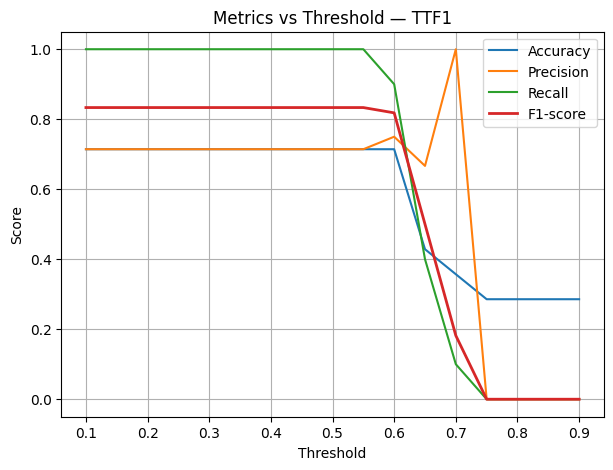

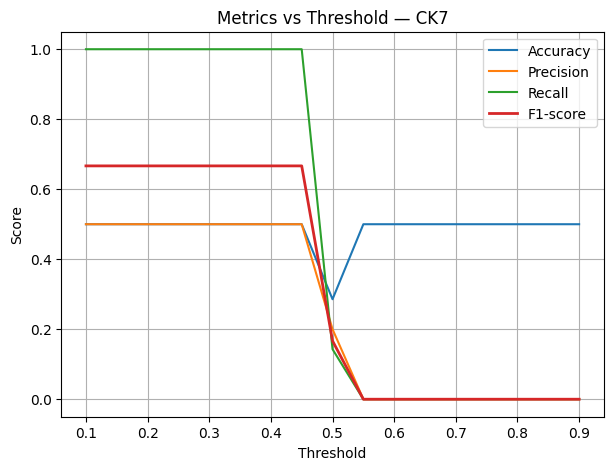

In [ ]:
MODEL_PATH = "/content/drive/MyDrive/Colab Notebooks/model_EfficientNet.keras"
model = tf.keras.models.load_model(MODEL_PATH)
print("Loaded model from:", MODEL_PATH)

y_true_ttf1, y_true_ck7 = [], []
for _, targets in test_ds.unbatch().map(lambda x, t: (0, t)):
    y_true_ttf1.append(float(targets["TTF1"].numpy()[0]))
    y_true_ck7.append(float(targets["CK7"].numpy()[0]))
y_true_ttf1 = np.array(y_true_ttf1, dtype=int)
y_true_ck7 = np.array(y_true_ck7, dtype=int)

pred = model.predict(test_ds, verbose=0)
p_test_ttf1 = pred["TTF1"].ravel()
p_test_ck7 = pred["CK7"].ravel()

def plot_threshold_metrics(y_true, y_prob, name):
    thresholds = np.arange(0.10, 0.91, 0.05)
    acc, prec, rec, f1 = [], [], [], []
    for t in thresholds:
        y_pred = (y_prob >= t).astype(int)
        acc.append(accuracy_score(y_true, y_pred))
        prec.append(precision_score(y_true, y_pred, zero_division=0))
        rec.append(recall_score(y_true, y_pred, zero_division=0))
        f1.append(f1_score(y_true, y_pred, zero_division=0))

    plt.figure(figsize=(7,5))
    plt.plot(thresholds, acc,  label="Accuracy")
    plt.plot(thresholds, prec, label="Precision")
    plt.plot(thresholds, rec,  label="Recall")
    plt.plot(thresholds, f1,   label="F1-score", linewidth=2)
    plt.xlabel("Threshold")
    plt.ylabel("Score")
    plt.title(f"Metrics vs Threshold — {name}")
    plt.legend()
    plt.grid(True)
    plt.show()

plot_threshold_metrics(y_true_ttf1,   p_test_ttf1,   "TTF1")
plot_threshold_metrics(y_true_ck7, p_test_ck7, "CK7")


/tmp/ipython-input-2589693549.py:3: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  y_true_ttf1.append(float(targets["TTF1"].numpy()))
/tmp/ipython-input-2589693549.py:4: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  y_true_ck7.append(float(targets["CK7"].numpy()))


7/7 ━━━━━━━━━━━━━━━━━━━━ 5s 658ms/step

TTF1 — binary metrics
Accuracy:  0.7143
Precision: 0.7500
Recall:    0.9000
F1-score:  0.8182
Confusion matrix [[TN FP] [FN TP]]:
[[1 3]
 [1 9]]


/usr/local/lib/python3.12/dist-packages/keras/src/trainers/epoch_iterator.py:160: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self._interrupted_warning()


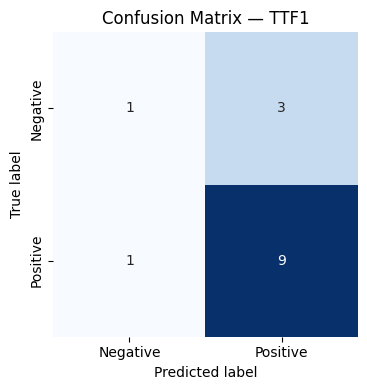


CK7 — binary metrics
Accuracy:  0.1429
Precision: 0.1429
Recall:    0.1429
F1-score:  0.1429
Confusion matrix [[TN FP] [FN TP]]:
[[1 6]
 [6 1]]


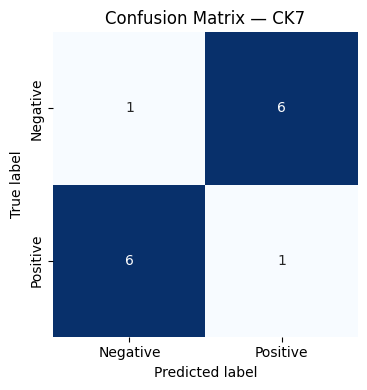

In [ ]:
y_true_ttf1, y_true_ck7 = [], []
for (_, _), targets in test_ds.unbatch():
    y_true_ttf1.append(float(targets["TTF1"].numpy()))
    y_true_ck7.append(float(targets["CK7"].numpy()))
y_true_ttf1 = np.array(y_true_ttf1, dtype=int)
y_true_ck7 = np.array(y_true_ck7, dtype=int)

pred = model.predict(test_ds)
y_pred_ttf1 = (pred["TTF1"].ravel()   >= 0.60).astype(int) # 6
y_pred_ck7 = (pred["CK7"].ravel() >= 0.48).astype(int)

def plot_confusion_matrix(y_true, y_pred, name):
    cm = confusion_matrix(y_true, y_pred)
    labels = ["Negative", "Positive"]

    plt.figure(figsize=(4.5, 4))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False,
                xticklabels=labels, yticklabels=labels, square=True)
    plt.xlabel("Predicted label")
    plt.ylabel("True label")
    plt.title(f"Confusion Matrix — {name}")
    plt.tight_layout()
    plt.show()

def print_binary_metrics(y_true, y_pred, name):
    acc = accuracy_score(y_true, y_pred)
    prec = precision_score(y_true, y_pred, zero_division=0)
    rec = recall_score(y_true, y_pred, zero_division=0)
    f1 = f1_score(y_true, y_pred, zero_division=0)
    cm = confusion_matrix(y_true, y_pred)

    print(f"\n{name} — binary metrics")
    print(f"Accuracy:  {acc:.4f}")
    print(f"Precision: {prec:.4f}")
    print(f"Recall:    {rec:.4f}")
    print(f"F1-score:  {f1:.4f}")
    print("Confusion matrix [[TN FP] [FN TP]]:")
    print(cm)

    plot_confusion_matrix(y_true, y_pred, name)

print_binary_metrics(y_true_ttf1,   y_pred_ttf1,   "TTF1")
print_binary_metrics(y_true_ck7, y_pred_ck7, "CK7")